In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os
import glob
import torch
import pandas as pd

BASE_PATH = "/kaggle/input/datasets/sangatichapla/bradd-s1/BraDD-S1TS_zenodo"
SAMPLES_PATH = os.path.join(BASE_PATH, "Samples")
META_PATH = os.path.join(BASE_PATH, "meta.csv")

meta = pd.read_csv(META_PATH)

train_meta = meta[
    meta["close_set"] == "train"
].copy()

validation_meta = meta[
    meta["close_set"] == "validation"
].copy()

test_meta = meta[
    meta["close_set"] == "test"
].copy()

print("Total:", len(meta))
print("Train:", len(train_meta))
print("Validation:", len(validation_meta))
print("Test:", len(test_meta))

print("\nFiles:", len(
    glob.glob(os.path.join(SAMPLES_PATH, "*.pt"))
))

sample_file = os.path.join(
    SAMPLES_PATH,
    train_meta.iloc[0]["file"]
)

data = torch.load(
    sample_file,
    map_location="cpu",
    weights_only=False
)

print("\nSample keys:", data.keys())
print("Image shape:", data["image"].shape)
print("Label shape:", data["label"].shape)
print("Number of SAR dates:", len(data["image_dates"]))
print("Number of label dates:", len(data["label_dates"]))
print("Image dtype:", data["image"].dtype)
print("Label values:", torch.unique(data["label"]))

Total: 25988
Train: 15625
Validation: 5112
Test: 5251

Files: 25988

Sample keys: dict_keys(['image_dates', 'label_dates', 'image', 'label'])
Image shape: torch.Size([31, 2, 48, 48])
Label shape: torch.Size([2, 48, 48])
Number of SAR dates: 31
Number of label dates: 2
Image dtype: torch.float32
Label values: tensor([0, 1])


In [2]:
from collections import Counter
import torch
import os

lengths = []
label_lengths = []

sample_check = []

for i, row in train_meta.iterrows():

    file_path = os.path.join(
        SAMPLES_PATH,
        row["file"]
    )

    data = torch.load(
        file_path,
        map_location="cpu",
        weights_only=False
    )

    lengths.append(
        len(data["image_dates"])
    )

    label_lengths.append(
        len(data["label_dates"])
    )

    if i < 5:
        sample_check.append({
            "file": row["file"],
            "sar_dates": len(data["image_dates"]),
            "label_dates": len(data["label_dates"])
        })

print("========== SAR SEQUENCE LENGTHS ==========")

count = Counter(lengths)

for length, number in sorted(count.items()):
    print(f"{length} dates: {number} samples")

print("\nMinimum SAR dates:", min(lengths))
print("Maximum SAR dates:", max(lengths))
print("Unique SAR lengths:", len(count))

print("\n========== LABEL SEQUENCE LENGTHS ==========")

print(
    Counter(label_lengths)
)

print("\n========== FIRST 5 SAMPLES ==========")

for item in sample_check:
    print(item)

========== SAR SEQUENCE LENGTHS ==========
10 dates: 1 samples
12 dates: 1 samples
13 dates: 1 samples
14 dates: 1 samples
15 dates: 1 samples
16 dates: 1 samples
17 dates: 1 samples
18 dates: 4 samples
19 dates: 7 samples
20 dates: 7 samples
21 dates: 14 samples
22 dates: 25 samples
23 dates: 48 samples
24 dates: 88 samples
25 dates: 183 samples
26 dates: 303 samples
27 dates: 434 samples
28 dates: 576 samples
29 dates: 795 samples
30 dates: 1411 samples
31 dates: 1888 samples
32 dates: 1613 samples
33 dates: 1203 samples
34 dates: 119 samples
35 dates: 130 samples
36 dates: 95 samples
37 dates: 57 samples
38 dates: 26 samples
39 dates: 16 samples
40 dates: 21 samples
41 dates: 38 samples
42 dates: 54 samples
43 dates: 53 samples
44 dates: 68 samples
45 dates: 86 samples
46 dates: 88 samples
47 dates: 127 samples
48 dates: 141 samples
49 dates: 269 samples
50 dates: 201 samples
51 dates: 238 samples
52 dates: 188 samples
53 dates: 202 samples
54 dates: 200 samples
55 dates: 220 sample

In [3]:
from torch.utils.data import Dataset, DataLoader
import torch
import os
import numpy as np

SAR_MEAN = torch.tensor(
    [-8.8265, -15.1540],
    dtype=torch.float32
)

SAR_STD = torch.tensor(
    [2.9952, 3.1455],
    dtype=torch.float32
)


class BraDDTemporalDataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        path = os.path.join(
            SAMPLES_PATH,
            row["file"]
        )

        data = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )

        image = data["image"].float()
        image = torch.nan_to_num(image)

        image_dates = data["image_dates"]

        order = np.argsort([
            d.toordinal() for d in image_dates
        ])

        image = image[
            torch.tensor(order, dtype=torch.long)
        ]

        image_dates = [
            image_dates[i] for i in order
        ]

        target_date = max(data["label_dates"])

        time = torch.tensor(
            [
                (target_date - d).days / 365.0
                for d in image_dates
            ],
            dtype=torch.float32
        )

        image = (
            image -
            SAR_MEAN[None, :, None, None]
        ) / SAR_STD[None, :, None, None]

        label = data["label"].long()

        label_order = np.argsort([
            d.toordinal()
            for d in data["label_dates"]
        ])

        label = label[
            torch.tensor(label_order, dtype=torch.long)
        ]

        label = label[-1]

        return image, label, time


def temporal_collate(batch):

    images, labels, times = zip(*batch)

    batch_size = len(images)
    max_t = max(x.shape[0] for x in images)

    padded_images = torch.zeros(
        batch_size,
        max_t,
        2,
        48,
        48
    )

    padded_times = torch.zeros(
        batch_size,
        max_t
    )

    temporal_mask = torch.ones(
        batch_size,
        max_t,
        dtype=torch.bool
    )

    for i in range(batch_size):

        t = images[i].shape[0]

        padded_images[i, :t] = images[i]
        padded_times[i, :t] = times[i]

        temporal_mask[i, :t] = False

    labels = torch.stack(labels)

    return (
        padded_images,
        labels,
        padded_times,
        temporal_mask
    )

In [5]:
client1 = train_meta[
    train_meta["state"] == "PA"
].copy()

client2 = train_meta[
    train_meta["state"].isin(["MT", "AM", "MA"])
].copy()

client3 = train_meta[
    train_meta["state"].isin(["RO", "AC", "RR", "AP", "TO"])
].copy()

clients = {
    "Client_1_PA": client1,
    "Client_2_MT_AM_MA": client2,
    "Client_3_RO_AC_RR_AP_TO": client3
}

print("========== CLIENTS ==========")

for name, df in clients.items():
    print(f"{name}: {len(df)} samples")

print("\nTotal client samples:",
      len(client1) + len(client2) + len(client3))

========== CLIENTS ==========
Client_1_PA: 7012 samples
Client_2_MT_AM_MA: 4320 samples
Client_3_RO_AC_RR_AP_TO: 4293 samples

Total client samples: 15625


In [6]:
temporal_dataset1 = BraDDTemporalDataset(client1)

images, masks, times, temporal_mask = temporal_collate([
    temporal_dataset1[0],
    temporal_dataset1[1],
    temporal_dataset1[2],
    temporal_dataset1[3]
])

print("Images:", images.shape)
print("Masks:", masks.shape)
print("Times:", times.shape)
print("Temporal mask:", temporal_mask.shape)

print("\nActual dates per sample:")
print((~temporal_mask).sum(dim=1).tolist())

print("\nMask values:")
print(torch.unique(masks))

Images: torch.Size([4, 31, 2, 48, 48])
Masks: torch.Size([4, 48, 48])
Times: torch.Size([4, 31])
Temporal mask: torch.Size([4, 31])

Actual dates per sample:
[31, 30, 31, 31]

Mask values:
tensor([0, 1])


In [7]:
from torch.utils.data import DataLoader

BATCH_SIZE = 8

client_loaders = {}

for name, df in clients.items():

    dataset = BraDDTemporalDataset(df)

    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        collate_fn=temporal_collate,
        pin_memory=torch.cuda.is_available()
    )

    client_loaders[name] = loader

    print(
        f"{name}: {len(dataset)} samples, "
        f"{len(loader)} batches"
    )


validation_dataset = BraDDTemporalDataset(
    validation_meta
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=temporal_collate,
    pin_memory=torch.cuda.is_available()
)


test_dataset = BraDDTemporalDataset(
    test_meta
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=temporal_collate,
    pin_memory=torch.cuda.is_available()
)


print("\nValidation:", len(validation_dataset))
print("Validation batches:", len(validation_loader))

print("Test:", len(test_dataset))
print("Test batches:", len(test_loader))

Client_1_PA: 7012 samples, 877 batches
Client_2_MT_AM_MA: 4320 samples, 540 batches
Client_3_RO_AC_RR_AP_TO: 4293 samples, 537 batches

Validation: 5112
Validation batches: 639
Test: 5251
Test batches: 657


In [8]:
for name, loader in client_loaders.items():

    images, masks, times, temporal_mask = next(iter(loader))

    print("\n" + name)
    print("Images:", images.shape)
    print("Masks:", masks.shape)
    print("Times:", times.shape)
    print("Temporal mask:", temporal_mask.shape)


Client_1_PA
Images: torch.Size([8, 33, 2, 48, 48])
Masks: torch.Size([8, 48, 48])
Times: torch.Size([8, 33])
Temporal mask: torch.Size([8, 33])

Client_2_MT_AM_MA
Images: torch.Size([8, 33, 2, 48, 48])
Masks: torch.Size([8, 48, 48])
Times: torch.Size([8, 33])
Temporal mask: torch.Size([8, 33])

Client_3_RO_AC_RR_AP_TO
Images: torch.Size([8, 65, 2, 48, 48])
Masks: torch.Size([8, 48, 48])
Times: torch.Size([8, 65])
Temporal mask: torch.Size([8, 65])


In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class DoubleConv(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                3,
                padding=1,
                bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_channels,
                out_channels,
                3,
                padding=1,
                bias=False
            ),
            nn.GroupNorm(8, out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class TemporalAttention(nn.Module):

    def __init__(self, channels):
        super().__init__()

        self.feature_score = nn.Linear(
            channels,
            1
        )

        self.time_score = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(inplace=True),
            nn.Linear(16, 1)
        )

    def forward(
        self,
        x,
        times,
        temporal_mask
    ):
        B, T, C, H, W = x.shape

        spatial_features = x.mean(
            dim=(-1, -2)
        )

        feature_scores = self.feature_score(
            spatial_features
        ).squeeze(-1)

        time_scores = self.time_score(
            times.unsqueeze(-1)
        ).squeeze(-1)

        scores = (
            feature_scores +
            time_scores
        )

        scores = scores.masked_fill(
            temporal_mask,
            -1e9
        )

        attention = torch.softmax(
            scores,
            dim=1
        )

        attention = attention.view(
            B,
            T,
            1,
            1,
            1
        )

        output = (
            x * attention
        ).sum(dim=1)

        return output


class TemporalAttentionUNet(nn.Module):

    def __init__(self):
        super().__init__()

        self.enc1 = DoubleConv(2, 32)
        self.enc2 = DoubleConv(32, 64)
        self.enc3 = DoubleConv(64, 128)

        self.attn1 = TemporalAttention(32)
        self.attn2 = TemporalAttention(64)
        self.attn3 = TemporalAttention(128)

        self.up2 = nn.ConvTranspose2d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec2 = DoubleConv(
            128,
            64
        )

        self.up1 = nn.ConvTranspose2d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec1 = DoubleConv(
            64,
            32
        )

        self.final = nn.Conv2d(
            32,
            1,
            kernel_size=1
        )

    def encode_frames(self, block, x):

        B, T, C, H, W = x.shape

        x = x.reshape(
            B * T,
            C,
            H,
            W
        )

        x = block(x)

        C2 = x.shape[1]
        H2 = x.shape[2]
        W2 = x.shape[3]

        x = x.reshape(
            B,
            T,
            C2,
            H2,
            W2
        )

        return x

    def forward(
        self,
        x,
        times,
        temporal_mask
    ):

        B, T, C, H, W = x.shape

        # Encoder level 1
        x1 = self.encode_frames(
            self.enc1,
            x
        )

        a1 = self.attn1(
            x1,
            times,
            temporal_mask
        )

        # Encoder level 2
        x1_flat = x1.reshape(
            B * T,
            32,
            H,
            W
        )

        x1_pool = F.max_pool2d(
            x1_flat,
            2
        )

        H2 = x1_pool.shape[-2]
        W2 = x1_pool.shape[-1]

        x1_pool = x1_pool.reshape(
            B,
            T,
            32,
            H2,
            W2
        )

        x2 = self.encode_frames(
            self.enc2,
            x1_pool
        )

        a2 = self.attn2(
            x2,
            times,
            temporal_mask
        )

        # Encoder level 3
        x2_flat = x2.reshape(
            B * T,
            64,
            H2,
            W2
        )

        x2_pool = F.max_pool2d(
            x2_flat,
            2
        )

        H3 = x2_pool.shape[-2]
        W3 = x2_pool.shape[-1]

        x2_pool = x2_pool.reshape(
            B,
            T,
            64,
            H3,
            W3
        )

        x3 = self.encode_frames(
            self.enc3,
            x2_pool
        )

        a3 = self.attn3(
            x3,
            times,
            temporal_mask
        )

        # Decoder
        d2 = self.up2(a3)

        d2 = torch.cat(
            [d2, a2],
            dim=1
        )

        d2 = self.dec2(d2)

        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, a1],
            dim=1
        )

        d1 = self.dec1(d1)

        return self.final(d1)

In [10]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

temporal_model = TemporalAttentionUNet().to(device)

images, masks, times, temporal_mask = next(
    iter(client_loaders["Client_3_RO_AC_RR_AP_TO"])
)

images = images.to(device)
times = times.to(device)
temporal_mask = temporal_mask.to(device)

with torch.no_grad():

    outputs = temporal_model(
        images,
        times,
        temporal_mask
    )

print("Device:", device)
print("Input :", images.shape)
print("Output:", outputs.shape)
print("Mask  :", masks.shape)

Device: cuda
Input : torch.Size([8, 65, 2, 48, 48])
Output: torch.Size([8, 1, 48, 48])
Mask  : torch.Size([8, 48, 48])


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class FocalLoss(nn.Module):

    def __init__(self, alpha=0.75, gamma=1.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma

    def forward(self, logits, targets):

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        probs = torch.sigmoid(logits)

        pt = (
            targets * probs +
            (1 - targets) * (1 - probs)
        )

        alpha_t = (
            targets * self.alpha +
            (1 - targets) * (1 - self.alpha)
        )

        loss = (
            alpha_t *
            (1 - pt) ** self.gamma *
            bce
        )

        return loss.mean()


class DiceLoss(nn.Module):

    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):

        probs = torch.sigmoid(logits)

        probs = probs.view(
            probs.size(0), -1
        )

        targets = targets.view(
            targets.size(0), -1
        )

        intersection = (
            probs * targets
        ).sum(dim=1)

        dice = (
            2 * intersection +
            self.smooth
        ) / (
            probs.sum(dim=1) +
            targets.sum(dim=1) +
            self.smooth
        )

        return 1 - dice.mean()


focal_loss = FocalLoss(
    alpha=0.75,
    gamma=1.0
)

dice_loss = DiceLoss()


def segmentation_loss(logits, targets):

    return (
        0.5 * focal_loss(logits, targets)
        +
        0.5 * dice_loss(logits, targets)
    )

In [12]:
images, masks, times, temporal_mask = next(
    iter(client_loaders["Client_1_PA"])
)

images = images.to(device)
masks = masks.float().unsqueeze(1).to(device)
times = times.to(device)
temporal_mask = temporal_mask.to(device)

outputs = temporal_model(
    images,
    times,
    temporal_mask
)

loss = segmentation_loss(
    outputs,
    masks
)

print("Temporal model loss:", loss.item())

Temporal model loss: 0.4857630133628845


In [13]:
import torch.optim as optim

local_model = TemporalAttentionUNet().to(device)

optimizer = optim.AdamW(
    local_model.parameters(),
    lr=1e-3,
    weight_decay=1e-6
)

num_epochs = 20

epoch_losses = []

for epoch in range(num_epochs):

    local_model.train()

    total_loss = 0.0

    for images, masks, times, temporal_mask in client_loaders["Client_1_PA"]:

        images = images.to(device, non_blocking=True)
        masks = masks.float().unsqueeze(1).to(device, non_blocking=True)
        times = times.to(device, non_blocking=True)
        temporal_mask = temporal_mask.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        outputs = local_model(
            images,
            times,
            temporal_mask
        )

        loss = segmentation_loss(
            outputs,
            masks
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            local_model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()

    avg_loss = (
        total_loss /
        len(client_loaders["Client_1_PA"])
    )

    epoch_losses.append(avg_loss)

    print(
        f"Epoch {epoch + 1}/{num_epochs} "
        f"- Loss: {avg_loss:.4f}"
    )

Epoch 1/20 - Loss: 0.4610
Epoch 2/20 - Loss: 0.4552
Epoch 3/20 - Loss: 0.4510
Epoch 4/20 - Loss: 0.4454
Epoch 5/20 - Loss: 0.4424
Epoch 6/20 - Loss: 0.4391
Epoch 7/20 - Loss: 0.4368
Epoch 8/20 - Loss: 0.4338
Epoch 9/20 - Loss: 0.4313
Epoch 10/20 - Loss: 0.4290
Epoch 11/20 - Loss: 0.4257
Epoch 12/20 - Loss: 0.4202
Epoch 13/20 - Loss: 0.3738
Epoch 14/20 - Loss: 0.1588
Epoch 15/20 - Loss: 0.1462
Epoch 16/20 - Loss: 0.1392
Epoch 17/20 - Loss: 0.1394
Epoch 18/20 - Loss: 0.1371
Epoch 19/20 - Loss: 0.1366
Epoch 20/20 - Loss: 0.1331


In [15]:
def evaluate_temporal_model(model, loader, device, threshold=0.5):

    model.eval()

    tp = fp = fn = tn = 0

    with torch.no_grad():

        for images, masks, times, temporal_mask in loader:

            images = images.to(device)
            masks = masks.float().to(device)
            times = times.to(device)
            temporal_mask = temporal_mask.to(device)

            outputs = model(
                images,
                times,
                temporal_mask
            )

            probabilities = torch.sigmoid(outputs)

            predictions = (
                probabilities >= threshold
            ).long()

            targets = masks.unsqueeze(1).long()

            tp += (
                (predictions == 1) &
                (targets == 1)
            ).sum().item()

            fp += (
                (predictions == 1) &
                (targets == 0)
            ).sum().item()

            fn += (
                (predictions == 0) &
                (targets == 1)
            ).sum().item()

            tn += (
                (predictions == 0) &
                (targets == 0)
            ).sum().item()

    iou = tp / max(tp + fp + fn, 1)

    dice = (
        2 * tp /
        max(2 * tp + fp + fn, 1)
    )

    precision = tp / max(tp + fp, 1)

    recall = tp / max(tp + fn, 1)

    accuracy = (
        tp + tn
    ) / max(
        tp + tn + fp + fn,
        1
    )

    predicted_positive = (
        (tp + fp) /
        max(tp + tn + fp + fn, 1)
    ) * 100

    return {
        "IoU": iou,
        "Dice": dice,
        "Precision": precision,
        "Recall": recall,
        "Accuracy": accuracy,
        "Predicted_positive_%": predicted_positive
    }


results = evaluate_temporal_model(
    local_model,
    validation_loader,
    device,
    threshold=0.5
)

print("========== CLIENT 1 TEMPORAL VALIDATION ==========")

for key, value in results.items():
    print(f"{key}: {value:.4f}")

========== CLIENT 1 TEMPORAL VALIDATION ==========
IoU: 0.5009
Dice: 0.6675
Precision: 0.5655
Recall: 0.8142
Accuracy: 0.8733
Predicted_positive_%: 22.4758


In [16]:
import copy
import torch.optim as optim

global_model = TemporalAttentionUNet().to(device)

client_states = []
client_sizes = []
client_losses = []
client_validation = []


for client_name, loader in client_loaders.items():

    print("\n" + "=" * 60)
    print(client_name)
    print("=" * 60)

    local_model = TemporalAttentionUNet().to(device)

    # Every client starts from the SAME global model
    local_model.load_state_dict(
        global_model.state_dict()
    )

    optimizer = optim.AdamW(
        local_model.parameters(),
        lr=1e-3,
        weight_decay=1e-6
    )

    epoch_losses = []

    for epoch in range(20):

        local_model.train()

        total_loss = 0.0

        for images, masks, times, temporal_mask in loader:

            images = images.to(device, non_blocking=True)

            masks = (
                masks.float()
                .unsqueeze(1)
                .to(device, non_blocking=True)
            )

            times = times.to(device, non_blocking=True)

            temporal_mask = temporal_mask.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad(
                set_to_none=True
            )

            outputs = local_model(
                images,
                times,
                temporal_mask
            )

            loss = segmentation_loss(
                outputs,
                masks
            )

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                local_model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

            total_loss += loss.item()

        avg_loss = (
            total_loss / len(loader)
        )

        epoch_losses.append(avg_loss)

        if (epoch + 1) % 5 == 0:
            print(
                f"Epoch {epoch + 1}/20 "
                f"- Loss: {avg_loss:.4f}"
            )

    local_result = evaluate_temporal_model(
        local_model,
        validation_loader,
        device,
        threshold=0.5
    )

    print("\nLocal validation:")
    print(f"IoU       : {local_result['IoU']:.4f}")
    print(f"Dice      : {local_result['Dice']:.4f}")
    print(f"Precision : {local_result['Precision']:.4f}")
    print(f"Recall    : {local_result['Recall']:.4f}")

    client_losses.append(
        epoch_losses[-1]
    )

    client_validation.append({
        "client": client_name,
        "loss": epoch_losses[-1],
        "IoU": local_result["IoU"],
        "Dice": local_result["Dice"],
        "Precision": local_result["Precision"],
        "Recall": local_result["Recall"]
    })

    client_sizes.append(
        len(loader.dataset)
    )

    client_states.append({
        k: v.detach().cpu().clone()
        for k, v in local_model.state_dict().items()
    })

    del local_model
    torch.cuda.empty_cache()


total_samples = sum(client_sizes)

global_state = {}

for key in client_states[0]:

    global_state[key] = sum(
        client_states[i][key].float()
        * (client_sizes[i] / total_samples)
        for i in range(len(client_states))
    ).to(
        client_states[0][key].dtype
    )


global_model.load_state_dict(
    global_state
)


client_results_df = pd.DataFrame(
    client_validation
)

print("\n" + "=" * 60)
print("CLIENT PERFORMANCE")
print("=" * 60)

display(
    client_results_df.sort_values(
        "IoU",
        ascending=False
    )
)


global_result = evaluate_temporal_model(
    global_model,
    validation_loader,
    device,
    threshold=0.5
)

print("GLOBAL MODEL AFTER ROUND 1")

for key, value in global_result.items():
    print(f"{key}: {value:.4f}")


Client_1_PA
Epoch 5/20 - Loss: 0.4472
Epoch 10/20 - Loss: 0.4333
Epoch 15/20 - Loss: 0.4244
Epoch 20/20 - Loss: 0.1488

Local validation:
IoU       : 0.4710
Dice      : 0.6404
Precision : 0.5089
Recall    : 0.8636

Client_2_MT_AM_MA
Epoch 5/20 - Loss: 0.4449
Epoch 10/20 - Loss: 0.4331
Epoch 15/20 - Loss: 0.4250
Epoch 20/20 - Loss: 0.2077

Local validation:
IoU       : 0.4379
Dice      : 0.6090
Precision : 0.4784
Recall    : 0.8377

Client_3_RO_AC_RR_AP_TO
Epoch 5/20 - Loss: 0.4368
Epoch 10/20 - Loss: 0.4270
Epoch 15/20 - Loss: 0.4200
Epoch 20/20 - Loss: 0.4114

Local validation:
IoU       : 0.3788
Dice      : 0.5495
Precision : 0.4435
Recall    : 0.7218

CLIENT PERFORMANCE


,client,loss,IoU,Dice,Precision,Recall
0,Client_1_PA,0.148782,0.471028,0.640406,0.508878,0.863627
1,Client_2_MT_AM_MA,0.207738,0.437858,0.609042,0.478443,0.837709
2,Client_3_RO_AC_RR_AP_TO,0.411352,0.378793,0.549456,0.443547,0.721808


GLOBAL MODEL AFTER ROUND 1
IoU: 0.0066
Dice: 0.0131
Precision: 0.8233
Recall: 0.0066
Accuracy: 0.8447
Predicted_positive_%: 0.1251


In [19]:
import copy
import torch
import torch.optim as optim

NUM_ROUNDS = 10
LOCAL_EPOCHS = 10
LR = 3e-4
WEIGHT_DECAY = 1e-6

torch.cuda.empty_cache()

global_model = TemporalAttentionUNet().to(device)

history = []
best_iou = -1.0


for round_no in range(1, NUM_ROUNDS + 1):

    print("\n")
    print(f"FEDERATED ROUND {round_no}/{NUM_ROUNDS}")

    client_states = []
    client_sizes = []
    client_losses = []
    client_results = []

    for client_name, loader in client_loaders.items():

        print("\n")
        print(client_name)

        local_model = TemporalAttentionUNet().to(device)

        local_model.load_state_dict(
            global_model.state_dict()
        )

        optimizer = optim.AdamW(
            local_model.parameters(),
            lr=LR,
            weight_decay=WEIGHT_DECAY
        )

        epoch_losses = []

        for epoch in range(LOCAL_EPOCHS):

            local_model.train()

            running_loss = 0.0

            for images, masks, times, temporal_mask in loader:

                images = images.to(
                    device,
                    non_blocking=True
                )

                masks = (
                    masks.float()
                    .unsqueeze(1)
                    .to(device, non_blocking=True)
                )

                times = times.to(
                    device,
                    non_blocking=True
                )

                temporal_mask = temporal_mask.to(
                    device,
                    non_blocking=True
                )

                optimizer.zero_grad(
                    set_to_none=True
                )

                outputs = local_model(
                    images,
                    times,
                    temporal_mask
                )

                loss = segmentation_loss(
                    outputs,
                    masks
                )

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    local_model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

                running_loss += loss.item()

            epoch_loss = (
                running_loss /
                len(loader)
            )

            epoch_losses.append(
                epoch_loss
            )

            if (epoch + 1) in [1, 5, 10]:

                print(
                    f"Epoch {epoch + 1}/{LOCAL_EPOCHS} "
                    f"- Loss: {epoch_loss:.4f}"
                )

        local_result = evaluate_temporal_model(
            local_model,
            validation_loader,
            device,
            threshold=0.5
        )

        print(
            f"Local IoU: {local_result['IoU']:.4f}"
        )

        print(
            f"Local Dice: {local_result['Dice']:.4f}"
        )

        client_losses.append(
            epoch_losses[-1]
        )

        client_sizes.append(
            len(loader.dataset)
        )

        client_results.append({
            "client": client_name,
            "loss": epoch_losses[-1],
            "IoU": local_result["IoU"],
            "Dice": local_result["Dice"],
            "Precision": local_result["Precision"],
            "Recall": local_result["Recall"]
        })

        client_states.append({
            k: v.detach().cpu().clone()
            for k, v in local_model.state_dict().items()
        })

        del local_model

        torch.cuda.empty_cache()


    total_samples = sum(client_sizes)

    global_state = {}

    for key in client_states[0]:

        global_state[key] = sum(
            client_states[i][key].float()
            * (
                client_sizes[i] /
                total_samples
            )
            for i in range(len(client_states))
        ).to(
            client_states[0][key].dtype
        )

    global_model.load_state_dict(
        global_state
    )


    global_result = evaluate_temporal_model(
        global_model,
        validation_loader,
        device,
        threshold=0.5
    )

    print("\n")
    print("GLOBAL VALIDATION")

    print(
        f"IoU: {global_result['IoU']:.4f}"
    )

    print(
        f"Dice: {global_result['Dice']:.4f}"
    )

    print(
        f"Precision: {global_result['Precision']:.4f}"
    )

    print(
        f"Recall: {global_result['Recall']:.4f}"
    )

    print(
        f"Accuracy: {global_result['Accuracy']:.4f}"
    )

    print(
        f"Predicted positive %: "
        f"{global_result['Predicted_positive_%']:.2f}"
    )


    round_record = {
        "round": round_no,

        "client1_loss": client_losses[0],
        "client2_loss": client_losses[1],
        "client3_loss": client_losses[2],

        "client1_iou": client_results[0]["IoU"],
        "client2_iou": client_results[1]["IoU"],
        "client3_iou": client_results[2]["IoU"],

        "global_iou": global_result["IoU"],
        "global_dice": global_result["Dice"],
        "global_precision": global_result["Precision"],
        "global_recall": global_result["Recall"],
        "global_accuracy": global_result["Accuracy"],
        "global_predicted_positive":
            global_result["Predicted_positive_%"]
    }

    history.append(
        round_record
    )


    if global_result["IoU"] > best_iou:

        best_iou = global_result["IoU"]

        best_state = {
            k: v.detach().cpu().clone()
            for k, v in global_model.state_dict().items()
        }

        torch.save(
            best_state,
            "/kaggle/working/best_temporal_federated_unet.pt"
        )

        print(
            f"BEST MODEL SAVED - IoU: {best_iou:.4f}"
        )


history_df = pd.DataFrame(
    history
)

history_df.to_csv(
    "/kaggle/working/temporal_federated_history.csv",
    index=False
)

print("\n")
print("TEMPORAL FEDERATED TRAINING COMPLETED")

display(
    history_df
)



FEDERATED ROUND 1/10


Client_1_PA
Epoch 1/10 - Loss: 0.4598
Epoch 5/10 - Loss: 0.4441
Epoch 10/10 - Loss: 0.4333
Local IoU: 0.3363
Local Dice: 0.5033


Client_2_MT_AM_MA
Epoch 1/10 - Loss: 0.4636
Epoch 5/10 - Loss: 0.4460
Epoch 10/10 - Loss: 0.4348
Local IoU: 0.2995
Local Dice: 0.4609


Client_3_RO_AC_RR_AP_TO
Epoch 1/10 - Loss: 0.4573
Epoch 5/10 - Loss: 0.4363
Epoch 10/10 - Loss: 0.4267
Local IoU: 0.3100
Local Dice: 0.4733


GLOBAL VALIDATION
IoU: 0.2237
Dice: 0.3657
Precision: 0.2373
Recall: 0.7964
Accuracy: 0.5686
Predicted positive %: 52.39
BEST MODEL SAVED - IoU: 0.2237


FEDERATED ROUND 2/10


Client_1_PA
Epoch 1/10 - Loss: 0.4402
Epoch 5/10 - Loss: 0.4300
Epoch 10/10 - Loss: 0.4230
Local IoU: 0.3327
Local Dice: 0.4993


Client_2_MT_AM_MA
Epoch 1/10 - Loss: 0.4401
Epoch 5/10 - Loss: 0.4314
Epoch 10/10 - Loss: 0.4252
Local IoU: 0.3426
Local Dice: 0.5104


Client_3_RO_AC_RR_AP_TO
Epoch 1/10 - Loss: 0.4322
Epoch 5/10 - Loss: 0.4227
Epoch 10/10 - Loss: 0.4154
Local IoU: 0.3367
Loc

,round,client1_loss,client2_loss,client3_loss,client1_iou,client2_iou,client3_iou,global_iou,global_dice,global_precision,global_recall,global_accuracy,global_predicted_positive
0,1,0.433318,0.434846,0.426690,0.336285,0.299462,0.309985,0.223737,0.365662,0.237310,0.796413,0.568644,52.390184
1,2,0.423005,0.425160,0.415423,0.332749,0.342612,0.336676,0.328047,0.494029,0.367255,0.754468,0.758748,32.070195
2,3,0.415014,0.416000,0.407058,0.367202,0.343893,0.388932,0.391297,0.562492,0.464450,0.713001,0.826852,23.965092
3,4,0.408328,0.409097,0.400726,0.396189,0.391493,0.341112,0.380749,0.551511,0.428235,0.774454,0.803370,28.231979
4,5,0.225632,0.225351,0.222629,0.439821,0.420858,0.415252,0.440227,0.611330,0.503345,0.778304,0.845506,24.138567
5,6,0.130372,0.135336,0.136973,0.471838,0.488584,0.492568,0.508787,0.674432,0.580124,0.805353,0.878620,21.671715
6,7,0.115689,0.108915,0.116097,0.504310,0.509738,0.507472,0.527022,0.690261,0.589547,0.832475,0.883370,22.043483
7,8,0.110894,0.101191,0.107354,0.521223,0.504972,0.525497,0.533255,0.695586,0.606705,0.814978,0.888643,20.969875
8,9,0.103320,0.100406,0.105375,0.521550,0.516377,0.515879,0.538100,0.699694,0.625503,0.793854,0.893622,19.812502
9,10,0.097895,0.093974,0.098849,0.505051,0.524828,0.526242,0.535896,0.697828,0.620813,0.796658,0.892295,20.032700


In [20]:

best_state = torch.load(
    "/kaggle/working/best_temporal_federated_unet.pt",
    map_location=device,
    weights_only=True
)

global_model.load_state_dict(best_state)
global_model = global_model.to(device)

thresholds = [
    0.30,
    0.35,
    0.40,
    0.45,
    0.50,
    0.55,
    0.60,
    0.65,
    0.70
]

threshold_results = []

for threshold in thresholds:

    result = evaluate_temporal_model(
        global_model,
        validation_loader,
        device,
        threshold=threshold
    )

    threshold_results.append({
        "threshold": threshold,
        "IoU": result["IoU"],
        "Dice": result["Dice"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "Accuracy": result["Accuracy"],
        "Predicted_%": result["Predicted_positive_%"]
    })


threshold_df = pd.DataFrame(
    threshold_results
)

print("VALIDATION THRESHOLD RESULTS")

display(threshold_df)

best_threshold_row = threshold_df.loc[
    threshold_df["IoU"].idxmax()
]

best_threshold = float(
    best_threshold_row["threshold"]
)

print("\nBEST VALIDATION THRESHOLD")
print(best_threshold_row)

print(
    f"\nSelected threshold: {best_threshold:.2f}"
)

VALIDATION THRESHOLD RESULTS


,threshold,IoU,Dice,Precision,Recall,Accuracy,Predicted_%
0,0.30,0.525371,0.688844,0.571634,0.866517,0.877794,23.663947
1,0.35,0.530416,0.693166,0.585596,0.849148,0.882643,22.636714
2,0.40,0.534214,0.696401,0.599070,0.831495,0.886823,21.667546
3,0.45,0.536697,0.698507,0.612237,0.813077,0.890429,20.731924
4,0.50,0.538100,0.699694,0.625503,0.793854,0.893622,19.812502
5,0.55,0.537952,0.699569,0.638795,0.773123,0.896338,18.893589
6,0.60,0.536627,0.698448,0.653077,0.750595,0.898821,17.941937
7,0.65,0.533437,0.695740,0.668307,0.725522,0.900938,16.947367
8,0.70,0.527576,0.690736,0.684896,0.696676,0.902612,15.879405



BEST VALIDATION THRESHOLD
threshold       0.500000
IoU             0.538100
Dice            0.699694
Precision       0.625503
Recall          0.793854
Accuracy        0.893622
Predicted_%    19.812502
Name: 4, dtype: float64

Selected threshold: 0.50


In [21]:
best_state = torch.load(
    "/kaggle/working/best_temporal_federated_unet.pt",
    map_location=device,
    weights_only=True
)

global_model.load_state_dict(best_state)
global_model = global_model.to(device)

final_test_results = evaluate_temporal_model(
    global_model,
    test_loader,
    device,
    threshold=0.50
)

print("\nFINAL TEMPORAL FEDERATED U-NET TEST")

for key, value in final_test_results.items():
    print(f"{key}: {value:.4f}")


FINAL TEMPORAL FEDERATED U-NET TEST
IoU: 0.5419
Dice: 0.7029
Precision: 0.6332
Recall: 0.7898
Accuracy: 0.8915
Predicted_positive_%: 20.2646


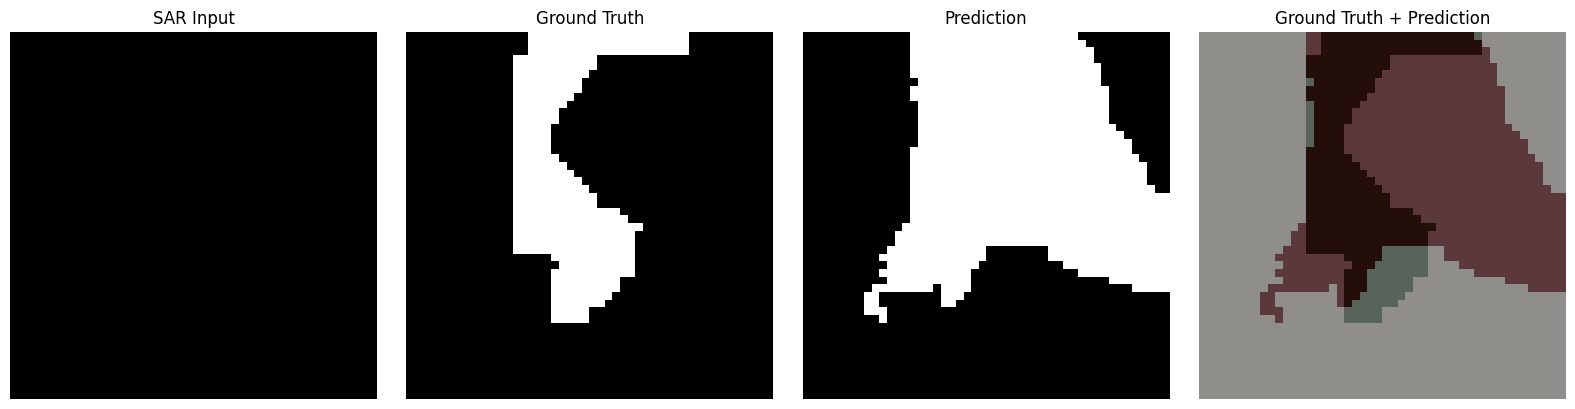

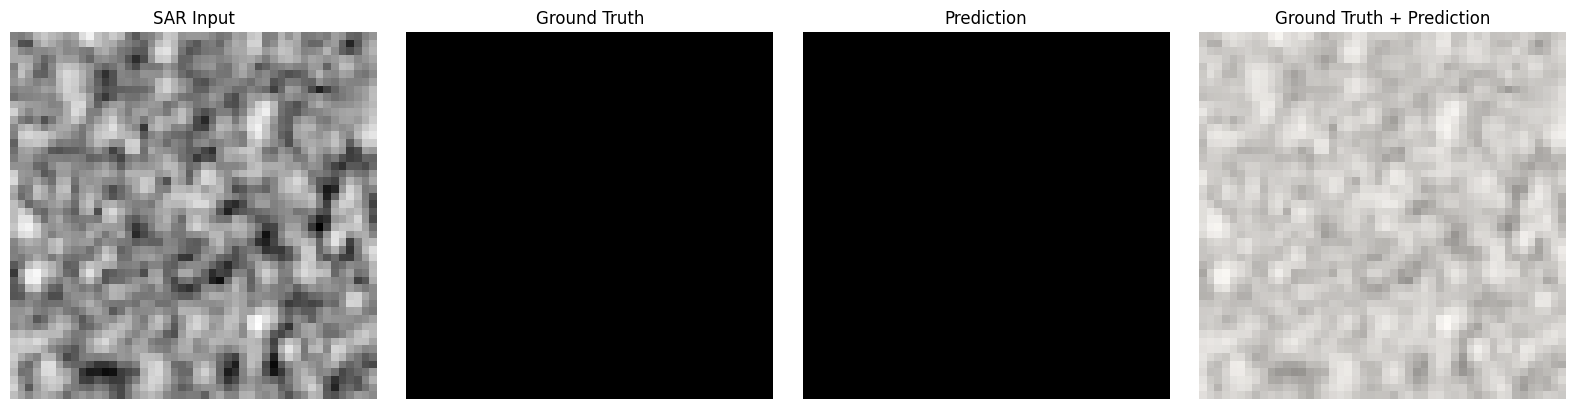

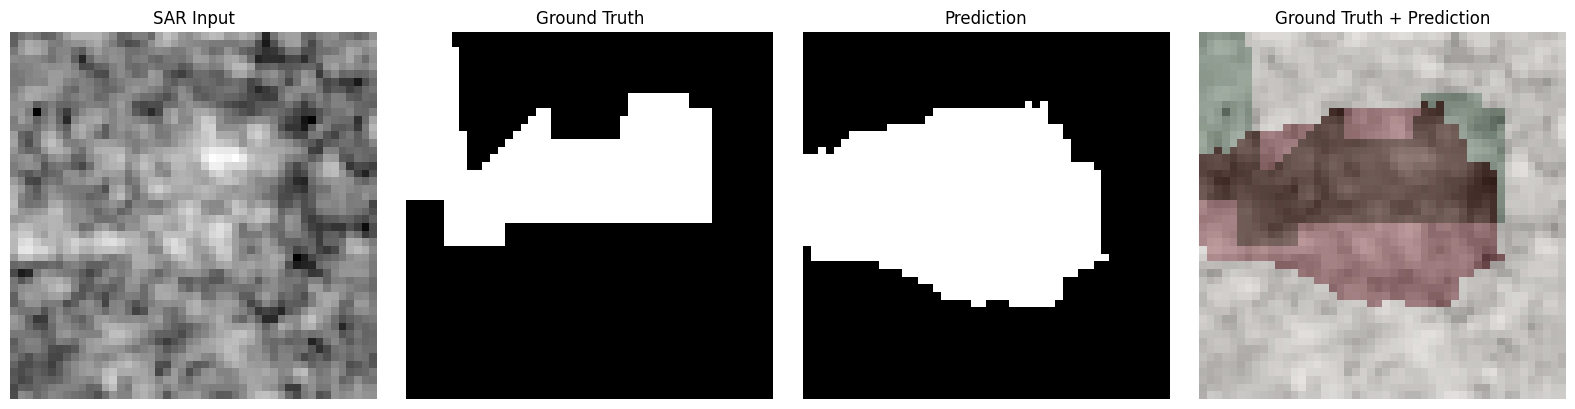

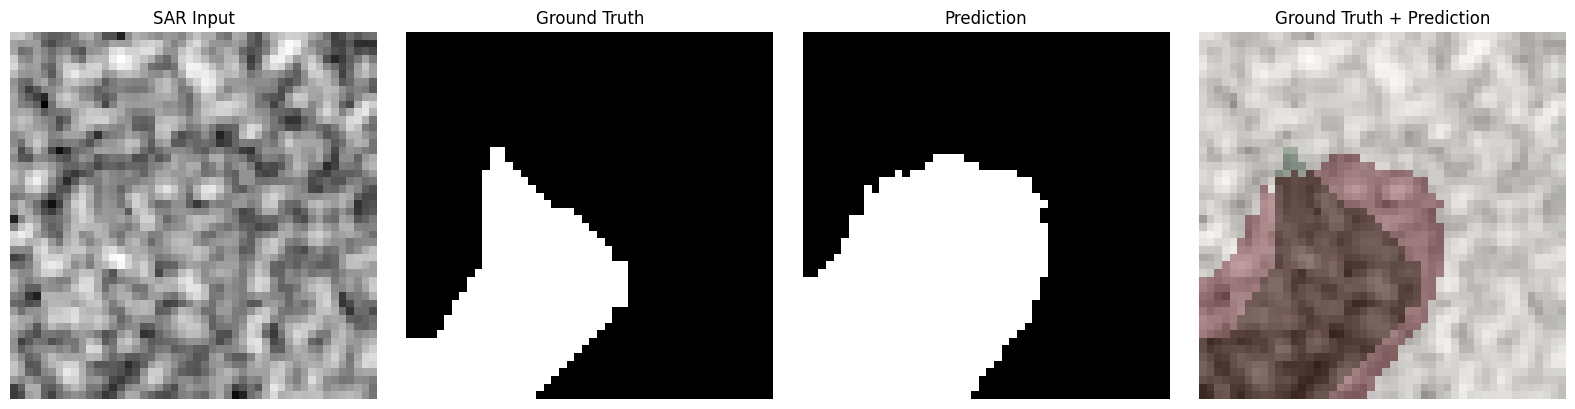

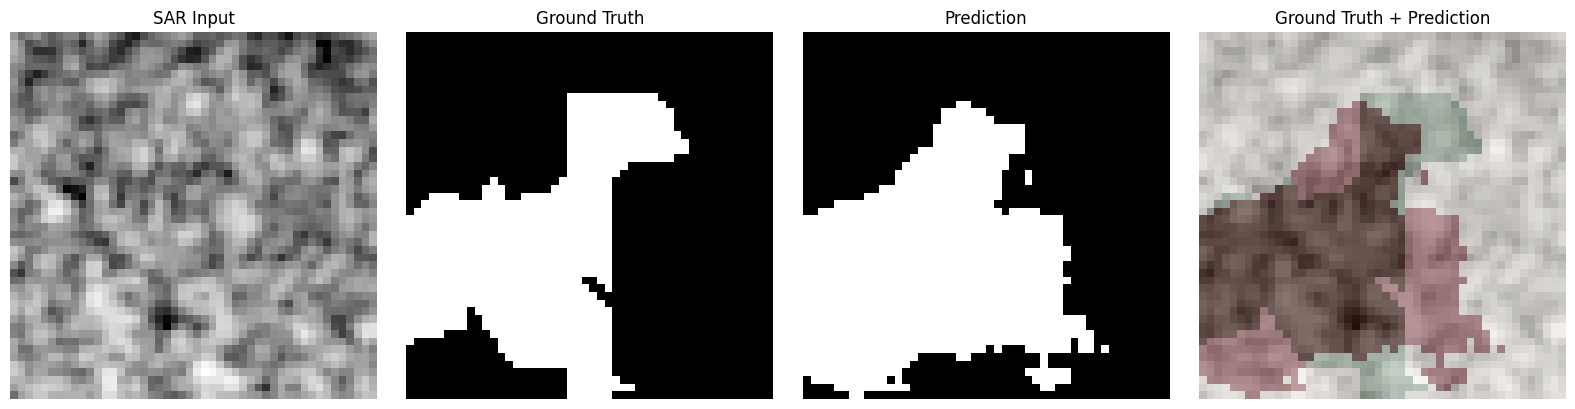

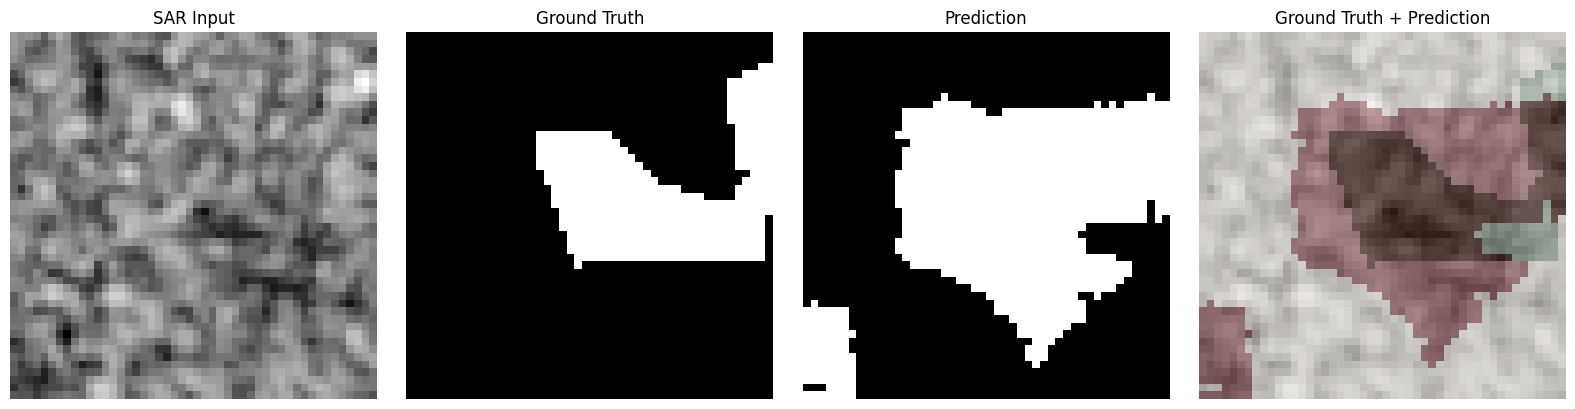

In [22]:
import matplotlib.pyplot as plt
import torch

global_model.eval()

images, masks, times, temporal_mask = next(iter(test_loader))

images = images.to(device)
times = times.to(device)
temporal_mask = temporal_mask.to(device)

with torch.no_grad():

    outputs = global_model(
        images,
        times,
        temporal_mask
    )

    probabilities = torch.sigmoid(outputs)

    predictions = (
        probabilities >= 0.50
    ).float()

# Move to CPU
images = images.cpu()
masks = masks.cpu()
predictions = predictions.cpu()
probabilities = probabilities.cpu()

# Show first 6 samples
num_samples = 6

for i in range(num_samples):

    # Use the last valid SAR date
    valid_dates = temporal_mask[i].cpu()

    last_date = int(
        valid_dates.sum().item()
    ) - 1

    sar = images[
        i,
        last_date,
        0
    ].numpy()

    ground_truth = masks[
        i
    ].numpy()

    prediction = predictions[
        i,
        0
    ].numpy()

    probability = probabilities[
        i,
        0
    ].numpy()

    plt.figure(figsize=(16, 4))

    plt.subplot(1, 4, 1)
    plt.imshow(sar, cmap="gray")
    plt.title("SAR Input")
    plt.axis("off")

    plt.subplot(1, 4, 2)
    plt.imshow(ground_truth, cmap="gray")
    plt.title("Ground Truth")
    plt.axis("off")

    plt.subplot(1, 4, 3)
    plt.imshow(prediction, cmap="gray")
    plt.title("Prediction")
    plt.axis("off")

    plt.subplot(1, 4, 4)
    plt.imshow(sar, cmap="gray")
    plt.imshow(
        ground_truth,
        cmap="Greens",
        alpha=0.35
    )
    plt.imshow(
        prediction,
        cmap="Reds",
        alpha=0.35
    )
    plt.title("Ground Truth + Prediction")
    plt.axis("off")

    plt.tight_layout()
    plt.show()